TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

NUMERICAL EXERCISE: h_t = tanh(Wx*x_t + Wh*h_{t-1} + b)
t=1: pre-activation = 0.350000 -> h1 = tanh(pre) = 0.336376
t=2: pre-activation = 0.719100 -> h2 = tanh(pre) = 0.616352
t=3: pre-activation = 0.693081 -> h3 = tanh(pre) = 0.599958
Manual  : [0.336376 0.616352 0.599958]
Keras   : [0.336376 0.616352 0.599958]
Match   : True
HAR root: /kaggle/working/har/UCI HAR Dataset

PREPROCESSING OUTPUT
Input tensor shape:
  Training   : (2100, 128, 9)
  Validation : (450, 128, 9)
  Testing    : (450, 128, 9)
Number of classes: 6
Number of features per time step: 9
Sequence length: 128
Class distribution (train/val/test):
                    train  val  test
WALKING               350   75    75
WALKING_UPSTAIRS      350   75    75
WALKING_DOWNSTAIRS    350   75    75
SITTING               350   75    75
STANDING              350   75    7

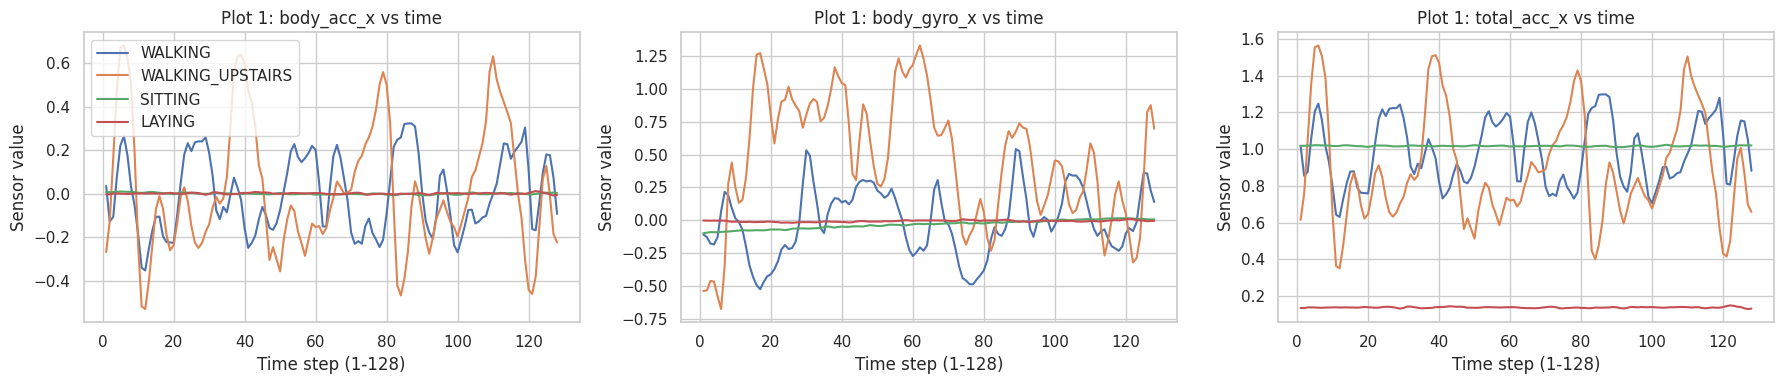


TRAINING RNN / LSTM / GRU ON HAR (T=128)
RNN   acc=74.00% f1=73.85% params=1,974 time=27.0s
LSTM  acc=93.56% f1=93.54% params=6,006 time=21.5s
GRU   acc=94.67% f1=94.65% params=4,758 time=21.2s


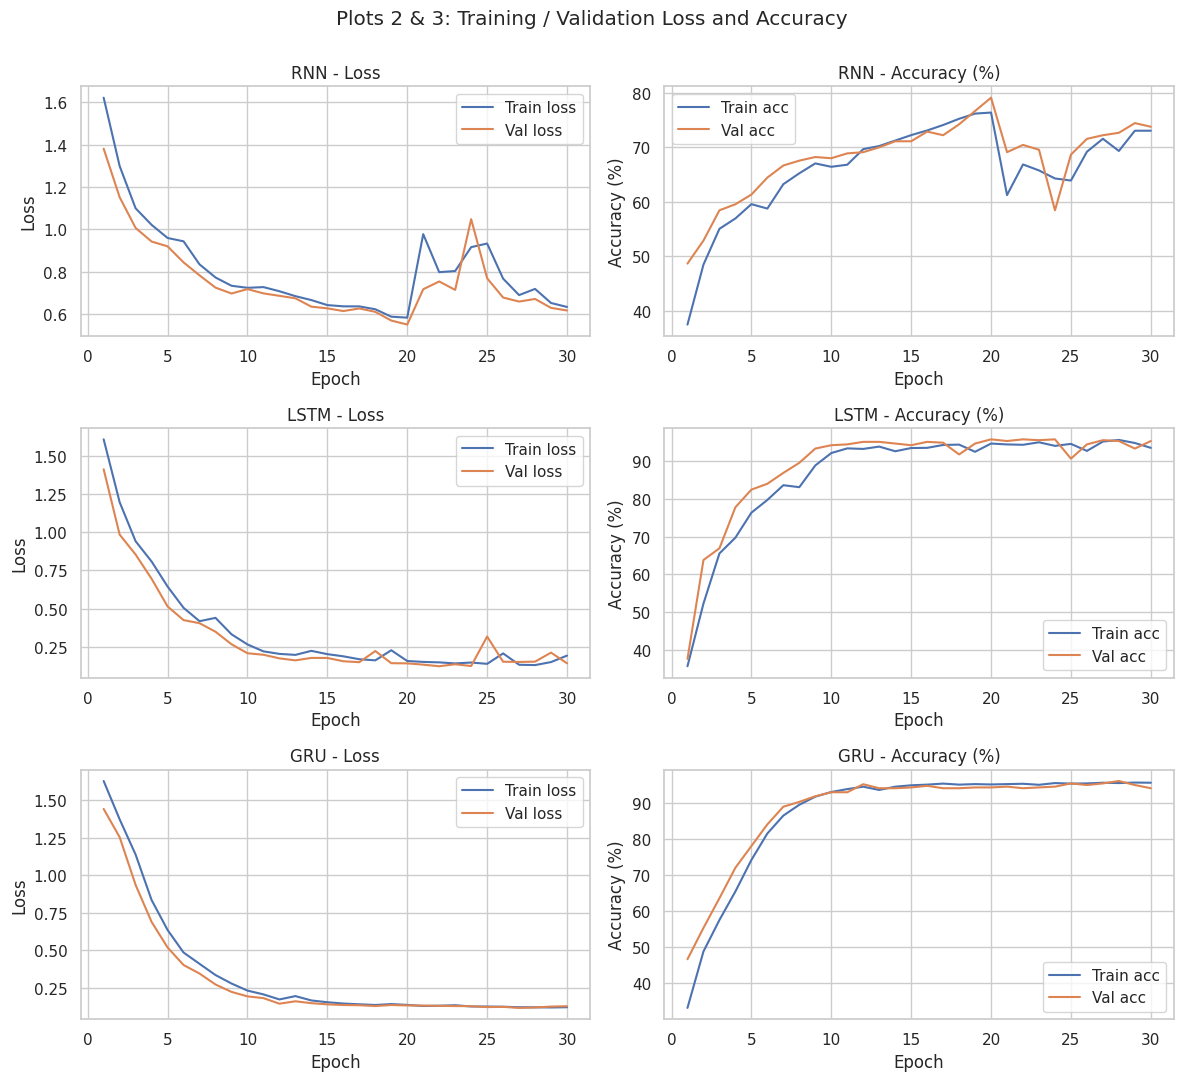

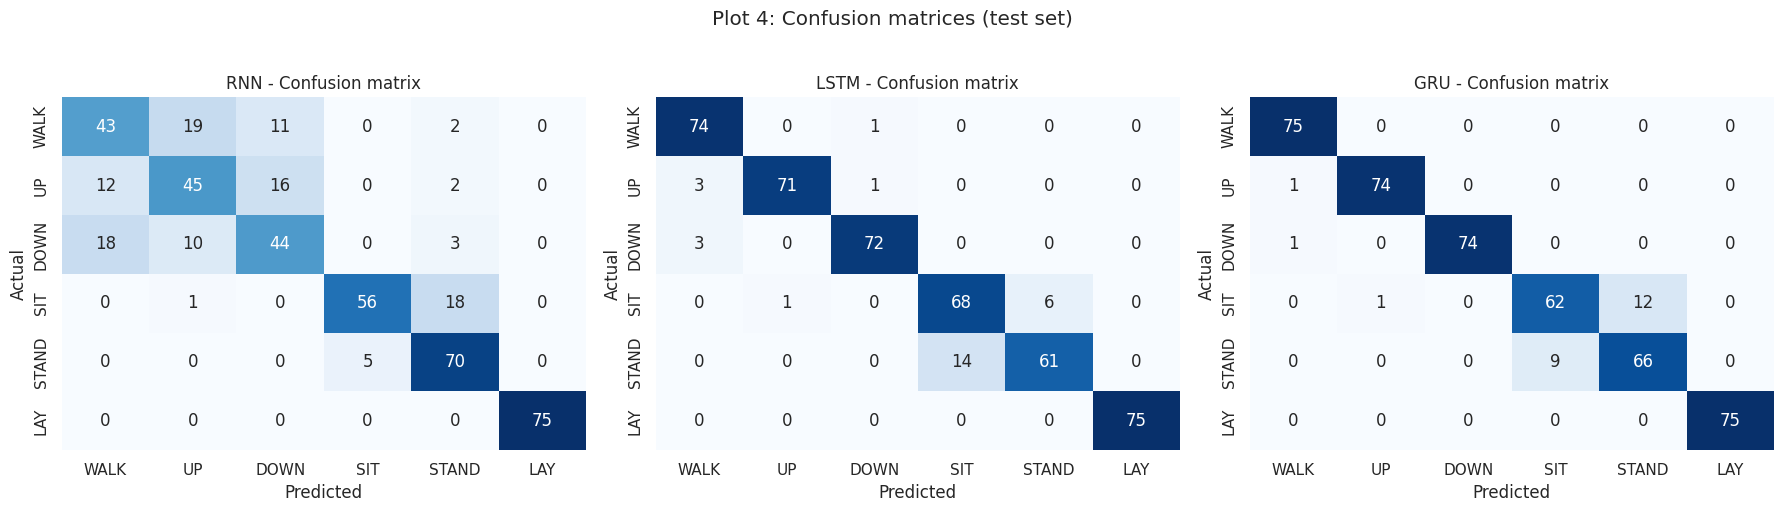


DATA-DRIVEN OBSERVATIONS (base your written inferences on these)
[RNN] final train/val acc = 73.0/73.8% | gap = -0.7 pp | val loss - train loss = -0.017
        val acc within 1pp of its best (epoch 20, 79.1%) from epoch 20 -> possible UNDERFITTING (train acc still low)
        best-recognised class: LAYING (100.0%) | most errors: WALKING (32 wrong)
        most confused pair: true WALKING -> predicted WALKING_UPSTAIRS (19 times)
[LSTM] final train/val acc = 93.5/95.3% | gap = -1.8 pp | val loss - train loss = -0.051
        val acc within 1pp of its best (epoch 20, 95.8%) from epoch 12 -> good fit / small generalization gap
        best-recognised class: LAYING (100.0%) | most errors: STANDING (14 wrong)
        most confused pair: true STANDING -> predicted SITTING (14 times)
[GRU] final train/val acc = 95.5/94.0% | gap = 1.5 pp | val loss - train loss = 0.007
        val acc within 1pp of its best (epoch 28, 96.0%) from epoch 12 -> good fit / small generalization gap
        best-r

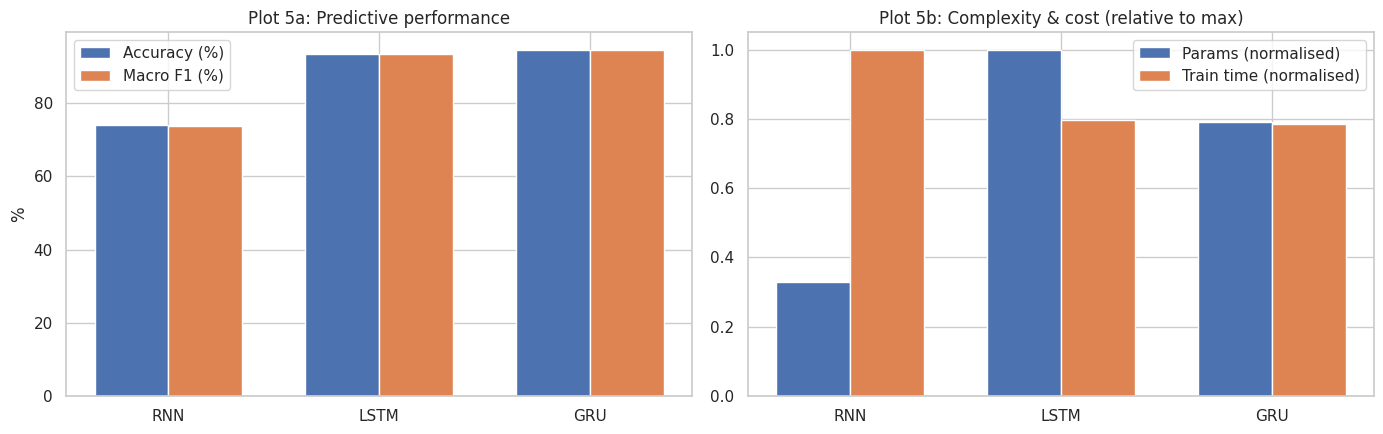


EFFECT OF SEQUENCE LENGTH
T=32 done
T=64 done
T=128 done
                 RNN F1  LSTM F1  GRU F1
Sequence Length                         
32                77.92    92.91   93.31
64                84.75    94.21   94.67
128               73.85    93.54   94.65

Training time (s) by sequence length:
      RNN  LSTM   GRU
32   17.6  16.9  16.6
64   19.8  18.2  18.3
128  27.0  21.5  21.2


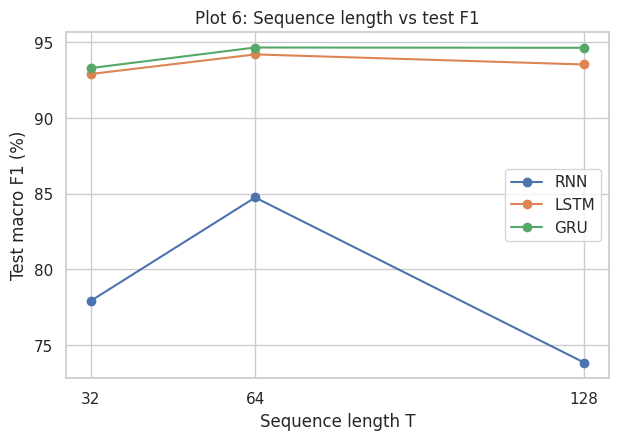


VIDEO UNDERSTANDING (CNN + RNN)
!! No .avi files in /kaggle/input -> using SYNTHETIC moving-square videos (pipeline demo only).
!! For the real experiment: Add Data -> a UCF101 dataset, then re-run.
  extracted 50/200 videos
  extracted 100/200 videos
  extracted 150/200 videos
  extracted 200/200 videos
CNN feature dimension D = 1280 | tensor given to recurrent net: (200, 10, 1280)  (B, 10, D)


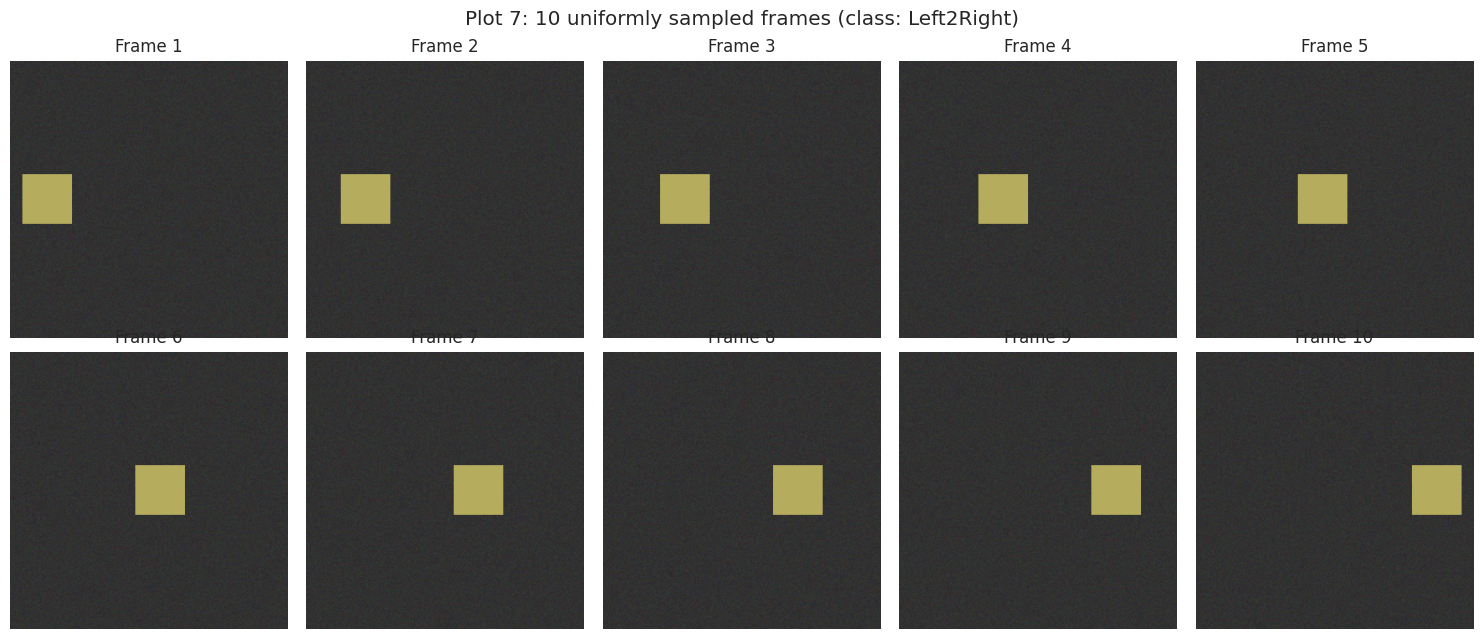

Video split: (140, 10, 1280) (30, 10, 1280) (30, 10, 1280)
CNN-LSTM: acc=100.00% f1=100.00% params(recurrent head)=168,677 time=7.8s
CNN-GRU: acc=100.00% f1=100.00% params(recurrent head)=126,757 time=7.7s


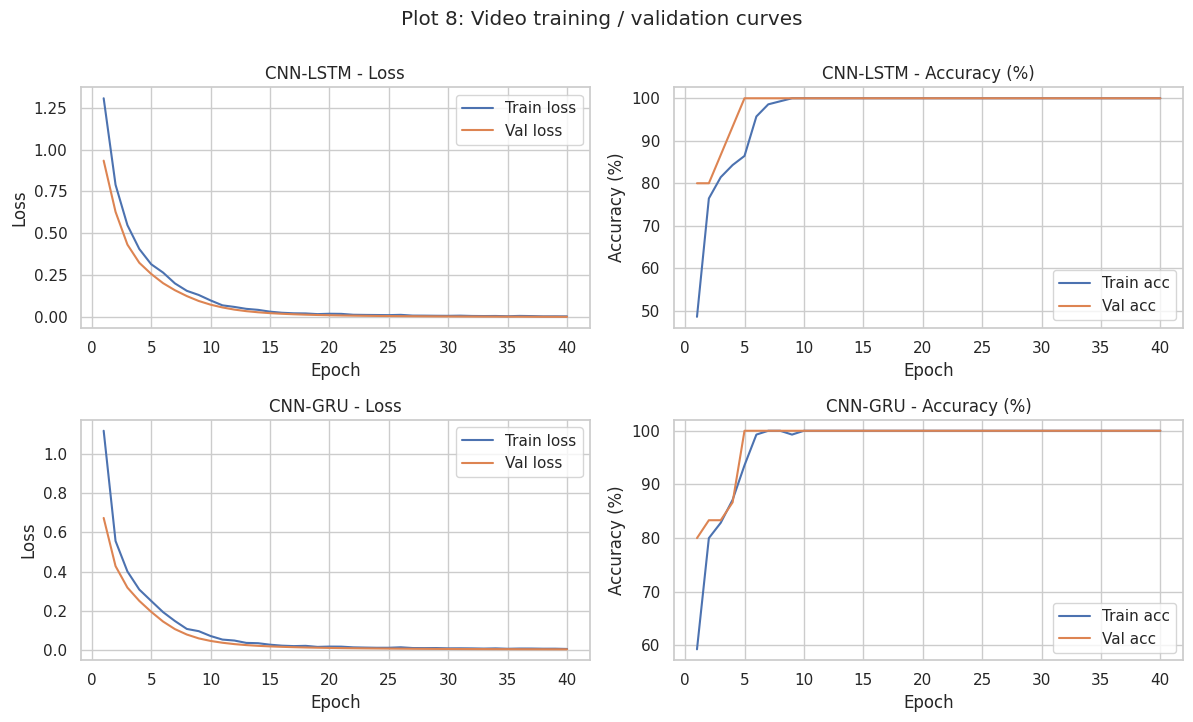

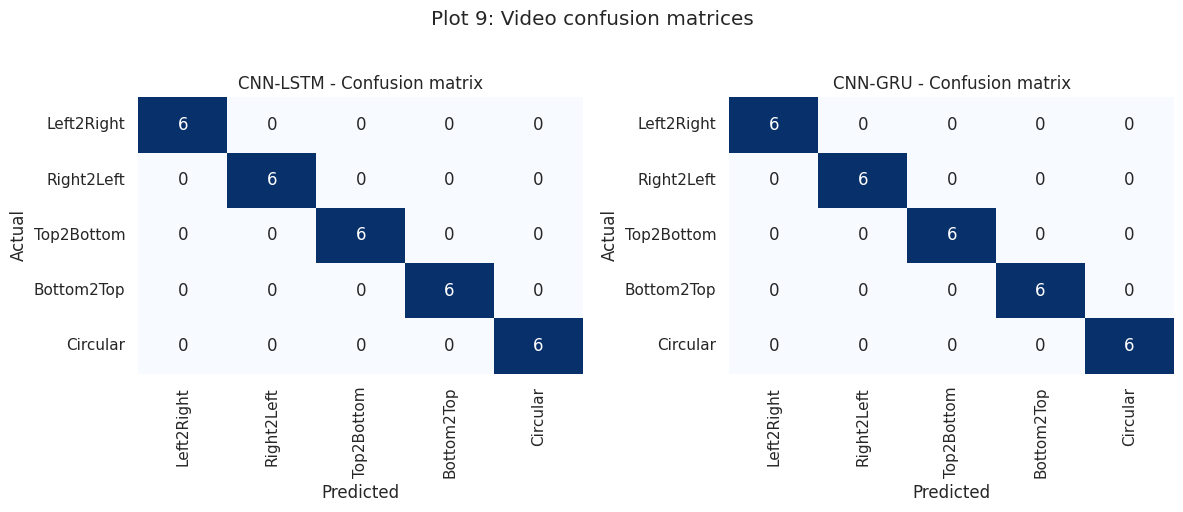

[CNN-LSTM] final train/val acc = 100.0/100.0% | gap = 0.0 pp | val loss - train loss = -0.003
        val acc within 1pp of its best (epoch 5, 100.0%) from epoch 5 -> good fit / small generalization gap
        best-recognised class: Left2Right (100.0%) | most errors: Left2Right (0 wrong)
        most confused pair: true Left2Right -> predicted Left2Right (0 times)
[CNN-GRU] final train/val acc = 100.0/100.0% | gap = 0.0 pp | val loss - train loss = -0.002
        val acc within 1pp of its best (epoch 5, 100.0%) from epoch 5 -> good fit / small generalization gap
        best-recognised class: Left2Right (100.0%) | most errors: Left2Right (0 wrong)
        most confused pair: true Left2Right -> predicted Left2Right (0 times)

Sample predictions (CNN-LSTM):
  Predicted class : Left2Right      Actual class : Left2Right      Confidence : 0.99
  Predicted class : Left2Right      Actual class : Left2Right      Confidence : 0.99
  Predicted class : Left2Right      Actual class : Left2Right  

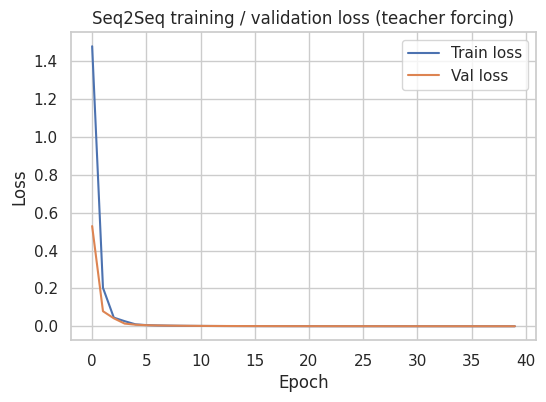


CONSOLIDATED RESULTS (test sets)
          Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  Parameters
RNN              74.00          74.39       74.00   73.85      1974.0
LSTM             93.56          93.73       93.56   93.54      6006.0
GRU              94.67          94.67       94.67   94.65      4758.0
CNN-LSTM        100.00         100.00      100.00  100.00    168677.0
CNN-GRU         100.00         100.00      100.00  100.00    126757.0

Seq2Seq table:
              Token Accuracy (%)  Sequence Accuracy (%)  Final Train Loss  Final Val Loss  Parameters
Seq2Seq LSTM               100.0                  100.0            0.0001          0.0002      166794

Total runtime: 4.5 min


In [2]:
# ==================================================================================
# CS3807 - Experiment 6 : RNN / LSTM / GRU  +  CNN-LSTM video  +  Seq2Seq
# Kaggle setup: Settings -> Accelerator = GPU, Internet = ON
# HAR data  : auto-found in /kaggle/input, else auto-downloaded from UCI
# Video data: uses UCF101 .avi files if you "Add Data" a UCF101 dataset
#             (e.g. search "ucf101 action recognition"); otherwise it falls back
#             to a SYNTHETIC moving-square video set so the pipeline still runs.
# ==================================================================================
import os, glob, re, time, zipfile, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
SEED = 42
def set_seed(): keras.utils.set_random_seed(SEED)
set_seed(); T_START = time.time()
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

# ----------------------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------------------
SUBSET_PER_CLASS = 500      # 500 x 6 = 3000 windows (lab subset). Set None for full dataset
EPOCHS, BATCH, UNITS = 30, 32, 32
KINDS = ["RNN", "LSTM", "GRU"]
ACT = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
ACT_S = ["WALK", "UP", "DOWN", "SIT", "STAND", "LAY"]
CH = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y", "body_gyro_z",
      "total_acc_x", "total_acc_y", "total_acc_z"]

# ==================================================================================
# 8. NUMERICAL EXERCISE (manual BPTT-style forward pass vs Keras)
# ==================================================================================
print("\n" + "=" * 80 + "\nNUMERICAL EXERCISE: h_t = tanh(Wx*x_t + Wh*h_{t-1} + b)\n" + "=" * 80)
xs, Wx, Wh, b = [0.5, 0.7, 0.2], 0.5, 0.8, 0.1
h, manual = 0.0, []
for i, xt in enumerate(xs, 1):
    pre = Wx * xt + Wh * h + b
    h = np.tanh(pre); manual.append(h)
    print(f"t={i}: pre-activation = {pre:.6f} -> h{i} = tanh(pre) = {h:.6f}")
_inp = keras.Input(shape=(3, 1)); _rnn = layers.SimpleRNN(1, activation="tanh", return_sequences=True)
_m = keras.Model(_inp, _rnn(_inp))
_rnn.set_weights([np.array([[Wx]]), np.array([[Wh]]), np.array([b])])
prog = _m.predict(np.array(xs, dtype="float32").reshape(1, 3, 1), verbose=0).ravel()
print("Manual  :", np.round(manual, 6)); print("Keras   :", np.round(prog, 6))
print("Match   :", np.allclose(manual, prog, atol=1e-5))

# ==================================================================================
# 3/5. LOAD UCI HAR RAW INERTIAL SIGNALS -> (N, 128, 9)
# ==================================================================================
def find_har_root():
    hits = [p for r in ["/kaggle/input", "/kaggle/working"]
            for p in glob.glob(f"{r}/**/body_acc_x_train.txt", recursive=True)]
    return os.path.dirname(os.path.dirname(os.path.dirname(hits[0]))) if hits else None

root = find_har_root()
if root is None:
    print("\nHAR raw signals not found in /kaggle/input -> downloading from UCI ...")
    url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
    os.makedirs("/kaggle/working/har", exist_ok=True); zp = "/kaggle/working/har/har.zip"
    urllib.request.urlretrieve(url, zp); zipfile.ZipFile(zp).extractall("/kaggle/working/har")
    for z in glob.glob("/kaggle/working/har/**/*.zip", recursive=True):
        if z != zp: zipfile.ZipFile(z).extractall("/kaggle/working/har")
    root = find_har_root()
assert root is not None, "Could not get HAR data. Turn Internet ON or add a UCI HAR dataset with Inertial Signals."
print("HAR root:", root)

def load_split(split):
    chans = []
    for sig in ["body_acc", "body_gyro", "total_acc"]:
        for ax in "xyz":
            f = f"{root}/{split}/Inertial Signals/{sig}_{ax}_{split}.txt"
            chans.append(pd.read_csv(f, sep=r"\s+", header=None).values.astype("float32"))
    X = np.stack(chans, axis=-1)                                   # (N,128,9)
    y = pd.read_csv(f"{root}/{split}/y_{split}.txt", header=None).values.ravel() - 1   # 0..5
    return X, y

Xa, ya = load_split("train"); Xb, yb = load_split("test")
X_all, y_all = np.concatenate([Xa, Xb]), np.concatenate([ya, yb])
rng = np.random.RandomState(SEED)
if SUBSET_PER_CLASS:                                               # balanced subset
    idx = np.concatenate([rng.choice(np.where(y_all == c)[0], SUBSET_PER_CLASS, replace=False) for c in range(6)])
    rng.shuffle(idx); X_all, y_all = X_all[idx], y_all[idx]

# 70 / 15 / 15 stratified split
Xtr, Xtmp, ytr, ytmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.50, stratify=ytmp, random_state=SEED)
Xraw_tr = Xtr.copy()
mu, sd = Xtr.mean(axis=(0, 1)), Xtr.std(axis=(0, 1)) + 1e-8        # train-only statistics
Xtr, Xva, Xte = [((a - mu) / sd).astype("float32") for a in (Xtr, Xva, Xte)]

print("\n" + "=" * 80 + "\nPREPROCESSING OUTPUT\n" + "=" * 80)
print("Input tensor shape:")
print(f"  Training   : {Xtr.shape}\n  Validation : {Xva.shape}\n  Testing    : {Xte.shape}")
print(f"Number of classes: 6\nNumber of features per time step: {Xtr.shape[2]}\nSequence length: {Xtr.shape[1]}")
print("Class distribution (train/val/test):")
print(pd.DataFrame({"train": np.bincount(ytr), "val": np.bincount(yva), "test": np.bincount(yte)}, index=ACT))

# ==================================================================================
# 6. PLOT 1 - TEMPORAL DATA VISUALIZATION
# ==================================================================================
show_cls, show_ch = [0, 1, 3, 5], [0, 3, 6]
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, c in zip(ax, show_ch):
    for k in show_cls:
        a.plot(range(1, 129), Xraw_tr[np.where(ytr == k)[0][0], :, c], label=ACT[k])
    a.set(title=f"Plot 1: {CH[c]} vs time", xlabel="Time step (1-128)", ylabel="Sensor value")
ax[0].legend(); plt.tight_layout(); plt.show()

# ==================================================================================
# 9-12. MODELS (identical except recurrent layer)
# ==================================================================================
def build_model(kind, T, F=9, n_classes=6):
    Rec = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[kind]
    m = keras.Sequential([keras.Input(shape=(T, F)), Rec(UNITS), layers.Dropout(0.2),
                          layers.Dense(16, activation="relu"), layers.Dense(n_classes, activation="softmax")], name=kind)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def n_trainable(m): return int(np.sum([np.prod(w.shape) for w in m.trainable_weights]))

def evaluate(m, X, y):
    yp = m.predict(X, verbose=0).argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, yp, average="macro", zero_division=0)
    return dict(acc=accuracy_score(y, yp) * 100, prec=p * 100, rec=r * 100, f1=f * 100), yp

def run_har(kind, T=128):
    keras.backend.clear_session(); set_seed()
    m = build_model(kind, T); t0 = time.time()
    h = m.fit(Xtr[:, :T], ytr, validation_data=(Xva[:, :T], yva), epochs=EPOCHS, batch_size=BATCH, verbose=0)
    tt = time.time() - t0
    met, yp = evaluate(m, Xte[:, :T], yte); met.update(params=n_trainable(m), time=tt)
    return dict(model=m, hist=h.history, met=met, yp=yp)

def plot_curves(R, title):
    fig, ax = plt.subplots(len(R), 2, figsize=(12, 3.6 * len(R)), squeeze=False)
    for i, (k, r) in enumerate(R.items()):
        h = r["hist"]; ep = np.arange(1, len(h["loss"]) + 1)
        ax[i, 0].plot(ep, h["loss"], label="Train loss"); ax[i, 0].plot(ep, h["val_loss"], label="Val loss")
        ax[i, 0].set(title=f"{k} - Loss", xlabel="Epoch", ylabel="Loss"); ax[i, 0].legend()
        ax[i, 1].plot(ep, np.array(h["accuracy"]) * 100, label="Train acc")
        ax[i, 1].plot(ep, np.array(h["val_accuracy"]) * 100, label="Val acc")
        ax[i, 1].set(title=f"{k} - Accuracy (%)", xlabel="Epoch", ylabel="Accuracy (%)"); ax[i, 1].legend()
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

def plot_cms(R, y_true, names, title):
    fig, ax = plt.subplots(1, len(R), figsize=(6 * len(R), 5), squeeze=False)
    for a, (k, r) in zip(ax[0], R.items()):
        cm = confusion_matrix(y_true, r["yp"], labels=range(len(names)))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=names, yticklabels=names, ax=a)
        a.set(title=f"{k} - Confusion matrix", xlabel="Predicted", ylabel="Actual")
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

def observe(name, r, y_true, names):
    """Data-driven facts from YOUR run - use them to write your inferences."""
    h = r["hist"]; va = np.array(h["val_accuracy"]) * 100; ta = np.array(h["accuracy"]) * 100
    conv = int(np.argmax(va >= va.max() - 1)) + 1
    cm = confusion_matrix(y_true, r["yp"], labels=range(len(names))); rec = cm.diagonal() / cm.sum(1)
    err = cm.sum(1) - cm.diagonal(); off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
    gap = ta[-1] - va[-1]
    verdict = ("possible UNDERFITTING (train acc still low)" if ta[-1] < 80 else
               "signs of OVERFITTING (large train-val gap)" if gap > 5 else "good fit / small generalization gap")
    print(f"[{name}] final train/val acc = {ta[-1]:.1f}/{va[-1]:.1f}% | gap = {gap:.1f} pp | "
          f"val loss - train loss = {h['val_loss'][-1] - h['loss'][-1]:.3f}")
    print(f"        val acc within 1pp of its best (epoch {va.argmax() + 1}, {va.max():.1f}%) from epoch {conv} -> {verdict}")
    print(f"        best-recognised class: {names[rec.argmax()]} ({rec.max() * 100:.1f}%) | most errors: {names[err.argmax()]} ({err.max()} wrong)")
    print(f"        most confused pair: true {names[i]} -> predicted {names[j]} ({off[i, j]} times)")

print("\n" + "=" * 80 + "\nTRAINING RNN / LSTM / GRU ON HAR (T=128)\n" + "=" * 80)
res = {}
for k in KINDS:
    res[k] = run_har(k, 128); m_ = res[k]["met"]
    print(f"{k:5s} acc={m_['acc']:.2f}% f1={m_['f1']:.2f}% params={m_['params']:,} time={m_['time']:.1f}s")

# Plots 2 & 3
plot_curves(res, "Plots 2 & 3: Training / Validation Loss and Accuracy")
# Plot 4
plot_cms(res, yte, ACT_S, "Plot 4: Confusion matrices (test set)")

print("\n" + "=" * 80 + "\nDATA-DRIVEN OBSERVATIONS (base your written inferences on these)\n" + "=" * 80)
for k in KINDS: observe(k, res[k], yte, ACT)

# 14. Performance table
perf = pd.DataFrame({k: {"Accuracy (%)": res[k]["met"]["acc"], "Macro Precision (%)": res[k]["met"]["prec"],
                         "Macro Recall (%)": res[k]["met"]["rec"], "Macro F1 (%)": res[k]["met"]["f1"],
                         "Parameters": res[k]["met"]["params"], "Training Time (s)": res[k]["met"]["time"]} for k in KINDS})
print("\nPERFORMANCE TABLE (test set)"); print(perf.round(2).to_string())

# 16. Comparison table
comp = pd.DataFrame({
    "Property": ["Hidden state", "Cell state", "Forget gate", "Input gate", "Output gate", "Update gate", "Reset gate",
                 "Parameters", "Training time (s)", "Test F1 (%)"],
    "RNN":  ["Yes", "No", "No", "No", "No", "No", "No", f"{res['RNN']['met']['params']:,}", f"{res['RNN']['met']['time']:.1f}", f"{res['RNN']['met']['f1']:.2f}"],
    "LSTM": ["Yes", "Yes", "Yes", "Yes", "Yes", "No", "No", f"{res['LSTM']['met']['params']:,}", f"{res['LSTM']['met']['time']:.1f}", f"{res['LSTM']['met']['f1']:.2f}"],
    "GRU":  ["Yes", "No", "No", "No", "No", "Yes", "Yes", f"{res['GRU']['met']['params']:,}", f"{res['GRU']['met']['time']:.1f}", f"{res['GRU']['met']['f1']:.2f}"]})
print("\nRNN vs LSTM vs GRU"); print(comp.to_string(index=False))

# Plot 5
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); w = 0.35; xi = np.arange(3)
ax[0].bar(xi - w / 2, [res[k]["met"]["acc"] for k in KINDS], w, label="Accuracy (%)")
ax[0].bar(xi + w / 2, [res[k]["met"]["f1"] for k in KINDS], w, label="Macro F1 (%)")
ax[0].set_xticks(xi); ax[0].set_xticklabels(KINDS); ax[0].set(title="Plot 5a: Predictive performance", ylabel="%"); ax[0].legend()
pm = max(res[k]["met"]["params"] for k in KINDS); tm = max(res[k]["met"]["time"] for k in KINDS)
ax[1].bar(xi - w / 2, [res[k]["met"]["params"] / pm for k in KINDS], w, label="Params (normalised)")
ax[1].bar(xi + w / 2, [res[k]["met"]["time"] / tm for k in KINDS], w, label="Train time (normalised)")
ax[1].set_xticks(xi); ax[1].set_xticklabels(KINDS); ax[1].set(title="Plot 5b: Complexity & cost (relative to max)"); ax[1].legend()
plt.tight_layout(); plt.show()

# ==================================================================================
# 17. EFFECT OF SEQUENCE LENGTH  (truncate to first T steps)
# ==================================================================================
print("\n" + "=" * 80 + "\nEFFECT OF SEQUENCE LENGTH\n" + "=" * 80)
f1T = {k: {} for k in KINDS}; tT = {k: {} for k in KINDS}
for T in [32, 64, 128]:
    for k in KINDS:
        r = res[k] if T == 128 else run_har(k, T)
        f1T[k][T] = r["met"]["f1"]; tT[k][T] = r["met"]["time"]
    print(f"T={T} done")
seq_tab = pd.DataFrame({f"{k} F1": f1T[k] for k in KINDS}); seq_tab.index.name = "Sequence Length"
print(seq_tab.round(2).to_string())
print("\nTraining time (s) by sequence length:"); print(pd.DataFrame(tT).round(1).to_string())
plt.figure(figsize=(7, 4.5))
for k in KINDS: plt.plot([32, 64, 128], [f1T[k][t] for t in [32, 64, 128]], marker="o", label=k)
plt.xticks([32, 64, 128]); plt.xlabel("Sequence length T"); plt.ylabel("Test macro F1 (%)")
plt.title("Plot 6: Sequence length vs test F1"); plt.legend(); plt.show()

# ==================================================================================
# 18-21. VIDEO UNDERSTANDING : MobileNetV2 (frozen) -> LSTM / GRU
# ==================================================================================
print("\n" + "=" * 80 + "\nVIDEO UNDERSTANDING (CNN + RNN)\n" + "=" * 80)
import cv2
N_FRAMES, VPC = 10, 40
PREF = ["Basketball", "Biking", "WalkingWithDog", "TennisSwing", "Diving"]
avis = glob.glob("/kaggle/input/**/*.avi", recursive=True)
USE_REAL = len(avis) > 0
rv = np.random.RandomState(SEED)

def read_frames(path, n=N_FRAMES, size=224):
    cap = cv2.VideoCapture(path); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idxs = np.linspace(0, max(total - 1, 0), n).astype(int); frames, last = [], None
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, f = cap.read()
        if ok: last = cv2.cvtColor(cv2.resize(f, (size, size)), cv2.COLOR_BGR2RGB)
        if last is None: last = np.zeros((size, size, 3), np.uint8)
        frames.append(last)
    cap.release(); return np.stack(frames)

def synth_frames(k, n=N_FRAMES, size=224):
    col = rv.randint(80, 255, 3); bg = rv.randint(0, 60); frames = []
    for t in range(n):
        u = t / (n - 1)
        if k == 0: cx, cy = 30 + 164 * u, 112
        elif k == 1: cx, cy = 194 - 164 * u, 112
        elif k == 2: cx, cy = 112, 30 + 164 * u
        elif k == 3: cx, cy = 112, 194 - 164 * u
        else: a = 2 * np.pi * u; cx, cy = 112 + 70 * np.cos(a), 112 + 70 * np.sin(a)
        img = np.full((size, size, 3), bg, np.uint8) + rv.randint(0, 15, (size, size, 3), dtype=np.uint8)
        x0, y0 = int(cx) - 20, int(cy) - 20
        img[max(y0, 0):y0 + 40, max(x0, 0):x0 + 40] = col; frames.append(img)
    return np.stack(frames)

if USE_REAL:
    by = {}
    for p in avis:
        mt = re.match(r"v_(.+?)_g\d+_c\d+", os.path.basename(p))
        if mt: by.setdefault(mt.group(1), []).append(p)
    vclasses = [c for c in PREF if c in by]
    for c in sorted(by):
        if len(vclasses) >= 5: break
        if c not in vclasses: vclasses.append(c)
    vclasses = vclasses[:5]; items, vlabels = [], []
    for k, c in enumerate(vclasses):
        ps = sorted(by[c]); sel = rv.choice(len(ps), min(VPC, len(ps)), replace=False)
        items += [ps[i] for i in sel]; vlabels += [k] * len(sel)
    print("Using REAL UCF101 videos. Classes:", vclasses, "| videos:", len(items))
else:
    vclasses = ["Left2Right", "Right2Left", "Top2Bottom", "Bottom2Top", "Circular"]
    items = [None] * (VPC * 5); vlabels = [k for k in range(5) for _ in range(VPC)]
    print("!! No .avi files in /kaggle/input -> using SYNTHETIC moving-square videos (pipeline demo only).")
    print("!! For the real experiment: Add Data -> a UCF101 dataset, then re-run.")
vlabels = np.array(vlabels); K = len(vclasses)

try:
    base = keras.applications.MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
except Exception as e:
    print("Could not download ImageNet weights (", e, ") -> using RANDOM weights (turn Internet ON!)")
    base = keras.applications.MobileNetV2(weights=None, include_top=False, pooling="avg", input_shape=(224, 224, 3))
base.trainable = False
prep = keras.applications.mobilenet_v2.preprocess_input

feats, sample_frames = [], None
for i, p in enumerate(items):
    fr = read_frames(p) if USE_REAL else synth_frames(int(vlabels[i]))
    if i == 0: sample_frames = fr.copy()
    feats.append(base.predict(prep(fr.astype("float32")), verbose=0))
    if (i + 1) % 50 == 0: print(f"  extracted {i + 1}/{len(items)} videos")
Xv = np.stack(feats).astype("float32"); D = Xv.shape[-1]
print(f"CNN feature dimension D = {D} | tensor given to recurrent net: {Xv.shape}  (B, {N_FRAMES}, D)")
del base

# Plot 7
fig, ax = plt.subplots(2, 5, figsize=(15, 6.5))
for i, a in enumerate(ax.ravel()): a.imshow(sample_frames[i]); a.set_title(f"Frame {i + 1}"); a.axis("off")
fig.suptitle(f"Plot 7: 10 uniformly sampled frames (class: {vclasses[vlabels[0]]})"); plt.tight_layout(); plt.show()

Vtr, Vtmp, vytr, vytmp = train_test_split(Xv, vlabels, test_size=0.30, stratify=vlabels, random_state=SEED)
Vva, Vte, vyva, vyte = train_test_split(Vtmp, vytmp, test_size=0.50, stratify=vytmp, random_state=SEED)
vm, vs = Vtr.mean(axis=(0, 1)), Vtr.std(axis=(0, 1)) + 1e-6
Vtr, Vva, Vte = [((a - vm) / vs).astype("float32") for a in (Vtr, Vva, Vte)]
print("Video split:", Vtr.shape, Vva.shape, Vte.shape)

def run_video(kind, epochs=40):
    keras.backend.clear_session(); set_seed()
    Rec = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([keras.Input(shape=(N_FRAMES, D)), Rec(32), layers.Dropout(0.3),
                          layers.Dense(16, activation="relu"), layers.Dense(K, activation="softmax")], name="CNN_" + kind)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(Vtr, vytr, validation_data=(Vva, vyva), epochs=epochs, batch_size=16, verbose=0)
    tt = time.time() - t0
    met, yp = evaluate(m, Vte, vyte); met.update(params=n_trainable(m), time=tt)
    return dict(model=m, hist=h.history, met=met, yp=yp)

vres = {f"CNN-{k}": run_video(k) for k in ["LSTM", "GRU"]}
for k, r in vres.items():
    print(f"{k}: acc={r['met']['acc']:.2f}% f1={r['met']['f1']:.2f}% params(recurrent head)={r['met']['params']:,} time={r['met']['time']:.1f}s")

plot_curves(vres, "Plot 8: Video training / validation curves")          # Plot 8
plot_cms(vres, vyte, vclasses, "Plot 9: Video confusion matrices")       # Plot 9
for k, r in vres.items(): observe(k, r, vyte, vclasses)

print("\nSample predictions (CNN-LSTM):")
pr = vres["CNN-LSTM"]["model"].predict(Vte[:5], verbose=0)
for i in range(len(pr)):
    print(f"  Predicted class : {vclasses[pr[i].argmax()]:15s} Actual class : {vclasses[vyte[i]]:15s} Confidence : {pr[i].max():.2f}")

# ==================================================================================
# 22-24. SEQ2SEQ : reversal with encoder-decoder LSTM (teacher forcing)
# ==================================================================================
print("\n" + "=" * 80 + "\nSEQ2SEQ REVERSAL TASK\n" + "=" * 80)
keras.backend.clear_session(); set_seed()
L, NS, V, SU = 6, 15000, 10, 128            # length, samples, vocab (0=START, 1..9 digits), LSTM units
rs = np.random.RandomState(SEED)
Xs = rs.randint(1, V, (NS, L)); Ys = Xs[:, ::-1].copy()
Din = np.concatenate([np.zeros((NS, 1), int), Ys[:, :-1]], axis=1)          # teacher forcing input
i1, i2 = int(0.8 * NS), int(0.9 * NS)
Xs_tr, Xs_va, Xs_te = Xs[:i1], Xs[i1:i2], Xs[i2:]
Ys_tr, Ys_va, Ys_te = Ys[:i1], Ys[i1:i2], Ys[i2:]
Di_tr, Di_va = Din[:i1], Din[i1:i2]

enc_in = keras.Input(shape=(L,)); enc_emb = layers.Embedding(V, 32)
_, eh, ec = layers.LSTM(SU, return_state=True)(enc_emb(enc_in))
dec_in = keras.Input(shape=(L,)); dec_emb = layers.Embedding(V, 32)
dec_lstm = layers.LSTM(SU, return_sequences=True, return_state=True); dec_dense = layers.Dense(V, activation="softmax")
dout, _, _ = dec_lstm(dec_emb(dec_in), initial_state=[eh, ec])
s2s = keras.Model([enc_in, dec_in], dec_dense(dout))
s2s.compile(optimizer=keras.optimizers.Adam(2e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hs = s2s.fit([Xs_tr, Di_tr], Ys_tr, validation_data=([Xs_va, Di_va], Ys_va), epochs=40, batch_size=128, verbose=0).history

# inference models (greedy step-by-step decoding, no teacher forcing)
enc_model = keras.Model(enc_in, [eh, ec])
tk = keras.Input(shape=(1,)); sh = keras.Input(shape=(SU,)); sc = keras.Input(shape=(SU,))
o, h2, c2 = dec_lstm(dec_emb(tk), initial_state=[sh, sc])
dec_model = keras.Model([tk, sh, sc], [dec_dense(o), h2, c2])

def decode(X):
    h, c = enc_model.predict(X, verbose=0); t = np.zeros((len(X), 1), int); out = []
    for _ in range(L):
        p, h, c = dec_model.predict([t, h, c], verbose=0)
        t = p[:, 0].argmax(-1)[:, None]; out.append(t[:, 0])
    return np.stack(out, axis=1)

pred = decode(Xs_te)
tok_acc = (pred == Ys_te).mean() * 100; seq_acc = (pred == Ys_te).all(axis=1).mean() * 100
print("Sample | Input Sequence | Expected | Predicted Output | Correct")
for i in range(5):
    print(f"  {i + 1}    | {list(Xs_te[i])} | {list(Ys_te[i])} | {list(pred[i])} | {bool((pred[i] == Ys_te[i]).all())}")
s2s_tab = pd.DataFrame({"Token Accuracy (%)": [tok_acc], "Sequence Accuracy (%)": [seq_acc],
                        "Final Train Loss": [hs["loss"][-1]], "Final Val Loss": [hs["val_loss"][-1]],
                        "Parameters": [n_trainable(s2s)]}, index=["Seq2Seq LSTM"])
print("\nSEQ2SEQ RESULTS"); print(s2s_tab.round(4).to_string())
print(f"Observed: token acc = {tok_acc:.2f}% but sequence acc = {seq_acc:.2f}%. "
      f"If tokens were independent, sequence acc ~ token_acc^L = {(tok_acc / 100) ** L * 100:.2f}% "
      f"-> one wrong token makes the whole sequence wrong.")
plt.figure(figsize=(6, 4)); plt.plot(hs["loss"], label="Train loss"); plt.plot(hs["val_loss"], label="Val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Seq2Seq training / validation loss (teacher forcing)"); plt.legend(); plt.show()

# ==================================================================================
# 25. CONSOLIDATED RESULTS
# ==================================================================================
rows = {k: res[k]["met"] for k in KINDS}; rows.update({k: v["met"] for k, v in vres.items()})
cons = pd.DataFrame(rows).T[["acc", "prec", "rec", "f1", "params"]]
cons.columns = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 (%)", "Parameters"]
print("\n" + "=" * 80 + "\nCONSOLIDATED RESULTS (test sets)\n" + "=" * 80)
print(cons.round(2).to_string())
print("\nSeq2Seq table:"); print(s2s_tab.round(4).to_string())
print(f"\nTotal runtime: {(time.time() - T_START) / 60:.1f} min")